⏳ Notebook execution started...
Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - loss: 0.0419 - val_loss: 0.0345
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0283 - val_loss: 0.0344
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0286 - val_loss: 0.0324
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0279 - val_loss: 0.0327
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0280 - val_loss: 0.0322
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0280 - val_loss: 0.0324
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0274 - val_loss: 0.0319
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0270 - val_loss: 0.0320
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0276 - val_loss: 0.0319
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0279 - val_loss: 0.0319
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0274 - val_loss: 0.0317
Epoch 12/30
14/14 ━━━━━━━━━━━━

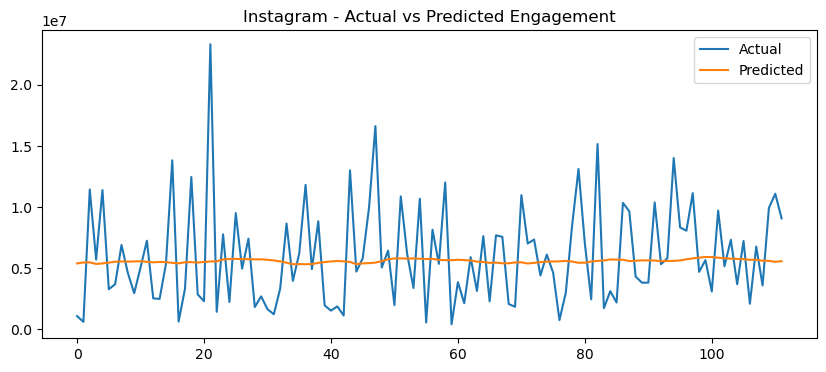

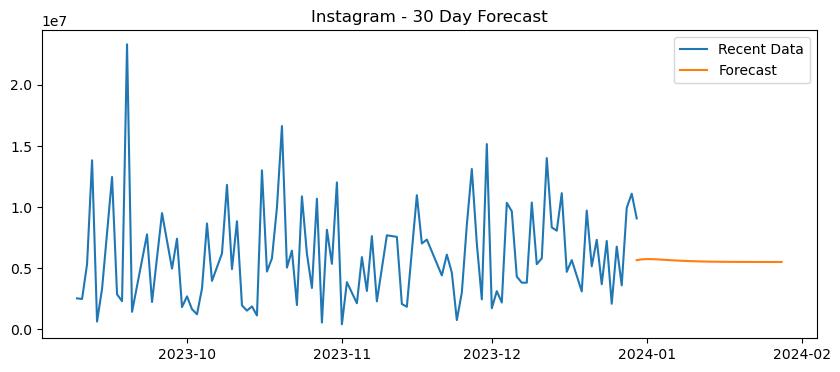

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 102ms/step - loss: 0.0554 - val_loss: 0.0330
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0322 - val_loss: 0.0315
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0320 - val_loss: 0.0311
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0322 - val_loss: 0.0310
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0322 - val_loss: 0.0309
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0317 - val_loss: 0.0307
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0320 - val_loss: 0.0307
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0318 - val_loss: 0.0307
Epoch 9/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0317 - val_loss: 0.0308
Epoch 10/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0311 - val_loss: 0.0307
Epoch 11/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0314 - val_loss: 0.0306
Epoch 12/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.

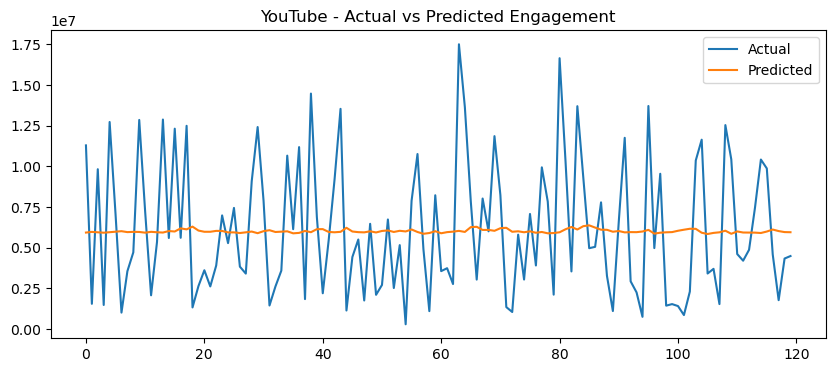

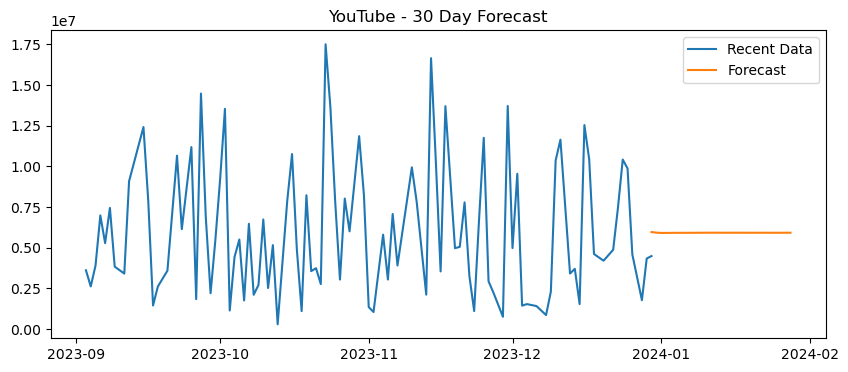

✅ Notebook finished in 1.46 minutes

🔍 Measuring prediction speed...

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
📌 Instagram Prediction Time: 0.2827 seconds
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
📌 YouTube Prediction Time: 0.2782 seconds


In [1]:
import time
start_time = time.time()
print("⏳ Notebook execution started...")

# -------------------------------------------------------
# Imports
# -------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from sklearn.metrics import mean_squared_error
import math
import tensorflow as tf

tf.random.set_seed(42)

# -------------------------------------------------------
# Load Data
# -------------------------------------------------------
df = pd.read_csv(r"D:\cleaned_Viral_Social_Media_Trends.csv")
df['Post_Date'] = pd.to_datetime(df['Post_Date'])

agg_df = df.groupby(['Post_Date', 'Platform'])[['Views', 'Likes', 'Shares', 'Comments']].sum().reset_index()

# -------------------------------------------------------
# Filter Instagram and YouTube
# -------------------------------------------------------
insta_df = agg_df[agg_df['Platform'].str.lower().str.contains('insta')].copy()
yt_df = agg_df[agg_df['Platform'].str.lower().str.contains('youtube')].copy()

insta_df = insta_df.sort_values('Post_Date')
yt_df = yt_df.sort_values('Post_Date')

# -------------------------------------------------------
# Engagement Score
# -------------------------------------------------------
insta_df['Engagement'] = insta_df[['Views', 'Likes', 'Shares', 'Comments']].sum(axis=1)
yt_df['Engagement'] = yt_df[['Views', 'Likes', 'Shares', 'Comments']].sum(axis=1)

insta_series = insta_df[['Post_Date', 'Engagement']].set_index('Post_Date')
yt_series = yt_df[['Post_Date', 'Engagement']].set_index('Post_Date')

# -------------------------------------------------------
# Sequence Creation Function
# -------------------------------------------------------
def create_sequences(values, look_back=30):
    X, y = [], []
    for i in range(len(values) - look_back):
        X.append(values[i:(i + look_back)])
        y.append(values[i + look_back])
    X = np.array(X)
    y = np.array(y)
    return X.reshape((X.shape[0], X.shape[1], 1)), y.reshape((-1, 1))

# -------------------------------------------------------
# LSTM Training Function
# -------------------------------------------------------
def train_lstm(series, label):

    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(series.values.reshape(-1, 1))

    look_back = 30
    X, y = create_sequences(scaled.flatten(), look_back)

    split = int(0.8 * len(X))
    X_train, X_val = X[:split], X[split:]
    y_train, y_val = y[:split], y[split:]

    model = Sequential([
        Input(shape=(look_back, 1)),
        LSTM(64, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')
    model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_data=(X_val, y_val),
        verbose=1
    )

    # -------------------------------------------------------
    # Validation Prediction
    # -------------------------------------------------------
    pred_val = model.predict(X_val)
    y_val_inv = scaler.inverse_transform(y_val)
    pred_val_inv = scaler.inverse_transform(pred_val)

    rmse = math.sqrt(mean_squared_error(y_val_inv, pred_val_inv))
    print(f"{label} Validation RMSE: {rmse:.2f}")

    # -------------------------------------------------------
    # Plot: Actual vs Predicted
    # -------------------------------------------------------
    plt.figure(figsize=(10, 4))
    plt.plot(y_val_inv, label='Actual')
    plt.plot(pred_val_inv, label='Predicted')
    plt.title(f"{label} - Actual vs Predicted Engagement")
    plt.legend()
    plt.show()

    # -------------------------------------------------------
    # Forecast Next 30 Days
    # -------------------------------------------------------
    forecast = []
    last_window = scaled[-look_back:].flatten()

    for _ in range(30):
        x_input = np.array(last_window[-look_back:]).reshape((1, look_back, 1))
        yhat = model.predict(x_input, verbose=0)[0][0]
        forecast.append(yhat)
        last_window = np.append(last_window, yhat)

    forecast_inv = scaler.inverse_transform(np.array(forecast).reshape(-1, 1))

    plt.figure(figsize=(10, 4))
    plt.plot(series.index[-100:], series.values[-100:], label='Recent Data')
    plt.plot(
        pd.date_range(series.index[-1], periods=30, freq='D'),
        forecast_inv,
        label='Forecast'
    )
    plt.title(f"{label} - 30 Day Forecast")
    plt.legend()
    plt.show()

    return model, X_val


# -------------------------------------------------------
# Train Models
# -------------------------------------------------------
insta_model = yt_model = None

if not insta_df.empty:
    insta_model, insta_X_val = train_lstm(insta_series['Engagement'], "Instagram")
else:
    print("⚠️ No Instagram data found.")

if not yt_df.empty:
    yt_model, yt_X_val = train_lstm(yt_series['Engagement'], "YouTube")
else:
    print("⚠️ No YouTube data found.")

end_time = time.time()
print(f"✅ Notebook finished in {(end_time - start_time)/60:.2f} minutes")


# -------------------------------------------------------
# CHECK MODEL PREDICTION SPEED
# -------------------------------------------------------
print("\n🔍 Measuring prediction speed...\n")

if insta_model:
    start_time = time.time()
    _ = insta_model.predict(insta_X_val)
    end_time = time.time()
    print("📌 Instagram Prediction Time:", round(end_time - start_time, 4), "seconds")

if yt_model:
    start_time = time.time()
    _ = yt_model.predict(yt_X_val)
    end_time = time.time()
    print("📌 YouTube Prediction Time:", round(end_time - start_time, 4), "seconds")



⏳ Notebook execution started...

Training Instagram LSTM...
Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0463 - val_loss: 0.0345
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0283 - val_loss: 0.0338
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0280 - val_loss: 0.0324
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0281 - val_loss: 0.0328
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0280 - val_loss: 0.0322
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0277 - val_loss: 0.0322
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0273 - val_loss: 0.0322
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0277 - val_loss: 0.0320
Epoch 9/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0274 - val_loss: 0.0320
Epoch 10/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0272 - val_loss: 0.0317
Epoch 11/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0274 - val_loss: 0.0318
Epo

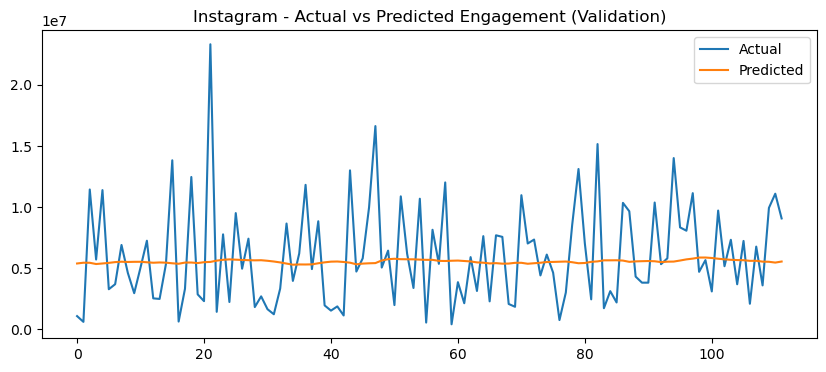

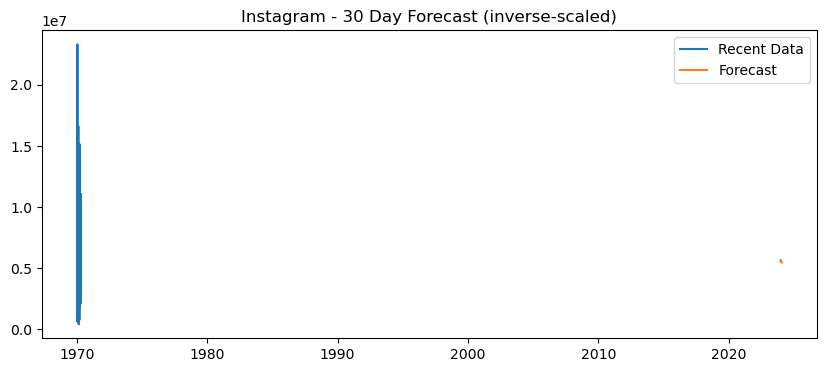


Training YouTube LSTM...
Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0568 - val_loss: 0.0352
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0323 - val_loss: 0.0320
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0330 - val_loss: 0.0312
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0318 - val_loss: 0.0311
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0320 - val_loss: 0.0308
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0314 - val_loss: 0.0308
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0314 - val_loss: 0.0307
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0309 - val_loss: 0.0307
Epoch 9/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0311 - val_loss: 0.0306
Epoch 10/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0312 - val_loss: 0.0305
Epoch 11/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0314 - val_loss: 0.0304
Epoch 12/30
15/15 ━━━━━━━━━━━━━━━━━━━

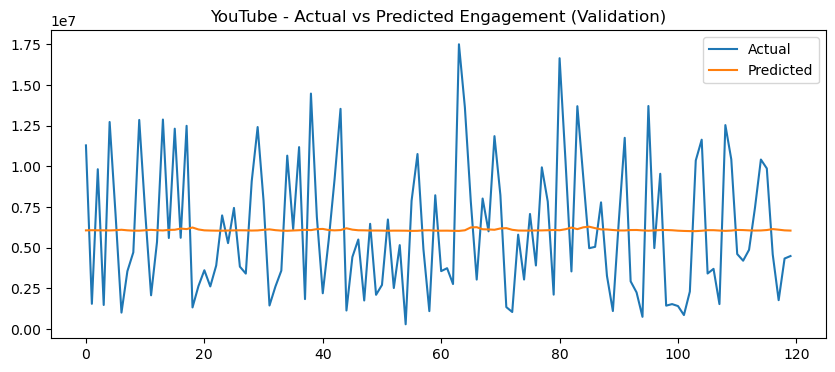

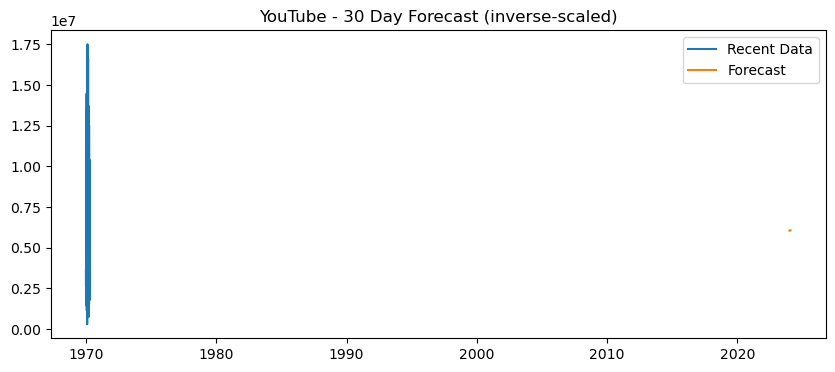


✅ Notebook finished in 1.22 minutes


📌 Running Tab 2 analysis...

--- Instagram : K = 5 ---
Best scale: 1000, Threshold used: 5000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[112]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       112

    accuracy                         1.0000       112
   macro avg     1.0000    1.0000    1.0000       112
weighted avg     1.0000    1.0000    1.0000       112



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


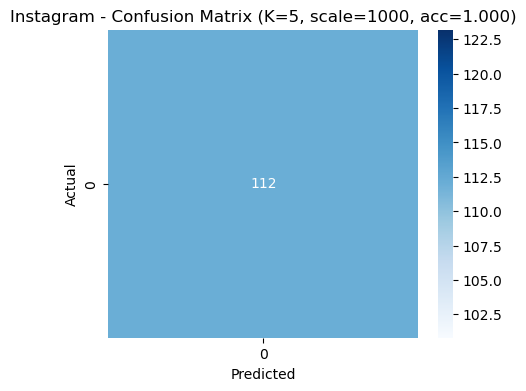


--- Instagram : K = 10 ---
Best scale: 1000, Threshold used: 10000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[112]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       112

    accuracy                         1.0000       112
   macro avg     1.0000    1.0000    1.0000       112
weighted avg     1.0000    1.0000    1.0000       112



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


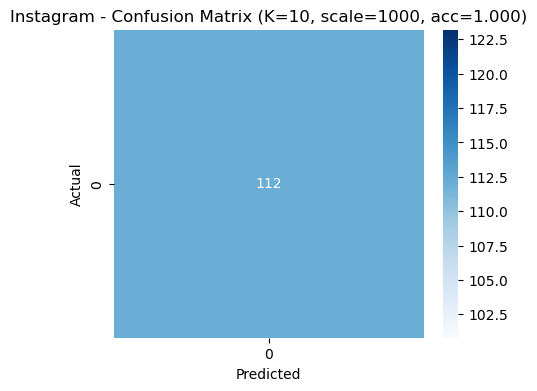


--- Instagram : K = 15 ---
Best scale: 1000, Threshold used: 15000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[112]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       112

    accuracy                         1.0000       112
   macro avg     1.0000    1.0000    1.0000       112
weighted avg     1.0000    1.0000    1.0000       112



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


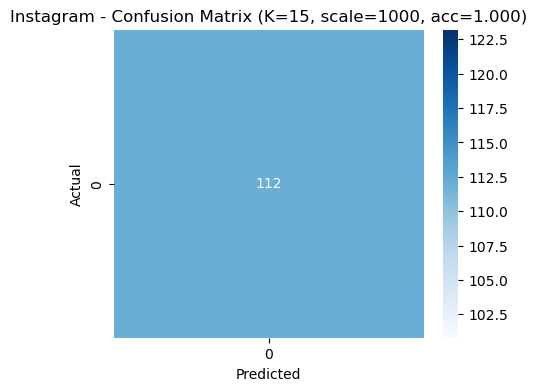


--- Instagram : K = 20 ---
Best scale: 1000, Threshold used: 20000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[112]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       112

    accuracy                         1.0000       112
   macro avg     1.0000    1.0000    1.0000       112
weighted avg     1.0000    1.0000    1.0000       112



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


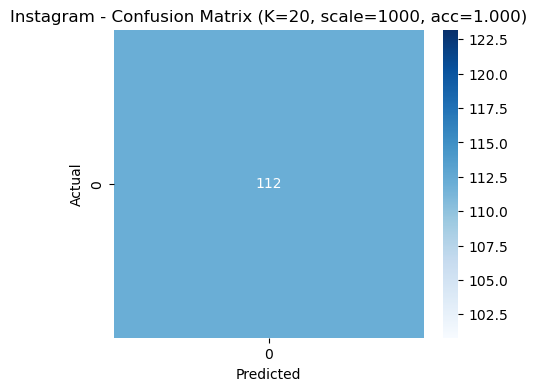


Instagram Summary:
       label   K  best_scale  threshold  accuracy    tn    fp    fn    tp
0  Instagram   5        1000       5000       1.0  None  None  None  None
1  Instagram  10        1000      10000       1.0  None  None  None  None
2  Instagram  15        1000      15000       1.0  None  None  None  None
3  Instagram  20        1000      20000       1.0  None  None  None  None

--- YouTube : K = 5 ---
Best scale: 1000, Threshold used: 5000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[120]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       120

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


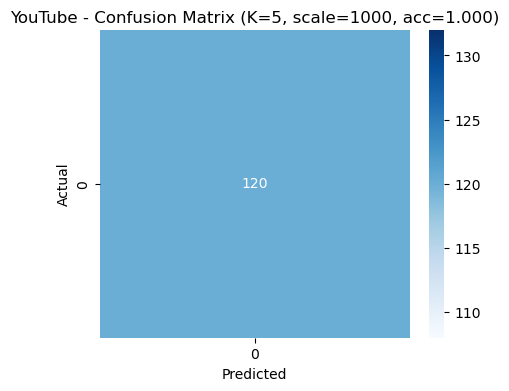


--- YouTube : K = 10 ---
Best scale: 1000, Threshold used: 10000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[120]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       120

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


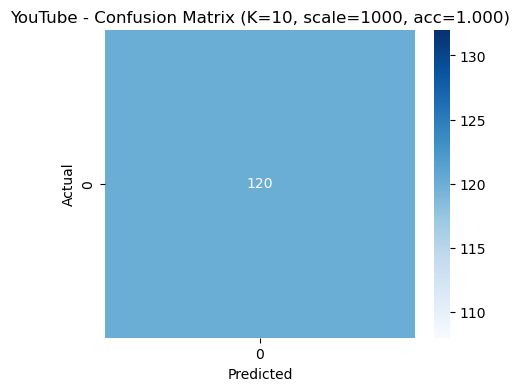


--- YouTube : K = 15 ---
Best scale: 1000, Threshold used: 15000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[120]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       120

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


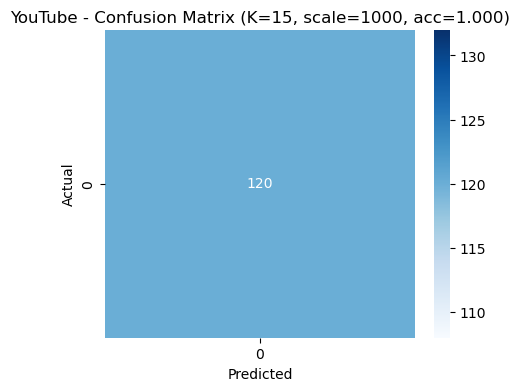


--- YouTube : K = 20 ---
Best scale: 1000, Threshold used: 20000, Achieved accuracy: 1.0000
Confusion Matrix:
 [[120]]

Classification Report:
               precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       120

    accuracy                         1.0000       120
   macro avg     1.0000    1.0000    1.0000       120
weighted avg     1.0000    1.0000    1.0000       120



C:\Users\Ankit kumar\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


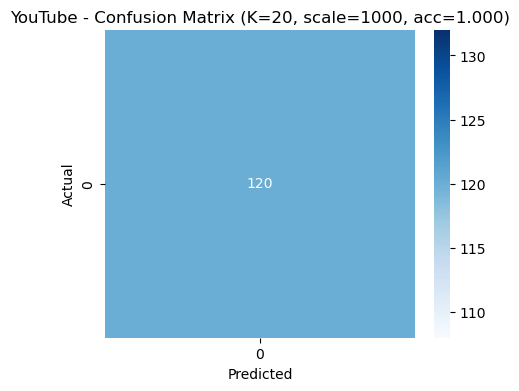


YouTube Summary:
     label   K  best_scale  threshold  accuracy    tn    fp    fn    tp
0  YouTube   5        1000       5000       1.0  None  None  None  None
1  YouTube  10        1000      10000       1.0  None  None  None  None
2  YouTube  15        1000      15000       1.0  None  None  None  None
3  YouTube  20        1000      20000       1.0  None  None  None  None


========== Combined Summary ==========
       label   K  best_scale  threshold  accuracy
0  Instagram   5        1000       5000       1.0
1  Instagram  10        1000      10000       1.0
2  Instagram  15        1000      15000       1.0
3  Instagram  20        1000      20000       1.0
4    YouTube   5        1000       5000       1.0
5    YouTube  10        1000      10000       1.0
6    YouTube  15        1000      15000       1.0
7    YouTube  20        1000      20000       1.0


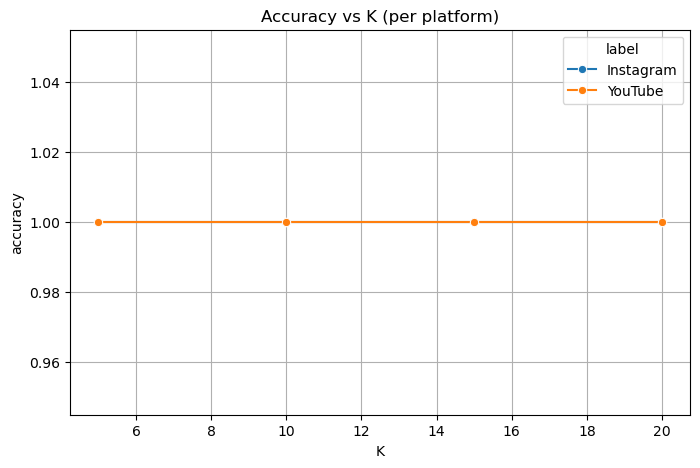


✅ Tab 2 finished in 0.08 minutes


In [2]:
# ---------------------- FULL FIXED CELL ----------------------
import time
start_time = time.time()
print("⏳ Notebook execution started...")

# -------------------------------------------------------
# Imports
# -------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from sklearn.metrics import mean_squared_error, confusion_matrix, classification_report, accuracy_score
import math
import tensorflow as tf

tf.random.set_seed(42)
np.random.seed(42)

# -------------------------------------------------------
# Load Data
# -------------------------------------------------------
df = pd.read_csv(r"D:\cleaned_Viral_Social_Media_Trends.csv")
df['Post_Date'] = pd.to_datetime(df['Post_Date'])

agg_df = df.groupby(['Post_Date', 'Platform'])[['Views', 'Likes', 'Shares', 'Comments']].sum().reset_index()

# -------------------------------------------------------
# Filter Instagram and YouTube (case-insensitive)
# -------------------------------------------------------
insta_df = agg_df[agg_df['Platform'].str.lower().str.contains('insta')].copy()
yt_df = agg_df[agg_df['Platform'].str.lower().str.contains('youtube')].copy()

insta_df = insta_df.sort_values('Post_Date')
yt_df = yt_df.sort_values('Post_Date')

# -------------------------------------------------------
# Engagement Score
# -------------------------------------------------------
insta_df['Engagement'] = insta_df[['Views', 'Likes', 'Shares', 'Comments']].sum(axis=1)
yt_df['Engagement'] = yt_df[['Views', 'Likes', 'Shares', 'Comments']].sum(axis=1)

insta_series = insta_df[['Post_Date', 'Engagement']].set_index('Post_Date')
yt_series = yt_df[['Post_Date', 'Engagement']].set_index('Post_Date')

# -------------------------------------------------------
# Sequence Creation Function
# -------------------------------------------------------
def create_sequences(values, look_back=30):
    X, y = [], []
    for i in range(len(values) - look_back):
        X.append(values[i:(i + look_back)])
        y.append(values[i + look_back])
    X = np.array(X)
    y = np.array(y)
    return X.reshape((X.shape[0], X.shape[1], 1)), y.reshape((-1, 1))

# -------------------------------------------------------
# LSTM Training Function (returns model and inverse-transformed y_val & pred_val)
# -------------------------------------------------------
def train_lstm(series, label, epochs=30, look_back=30):
    # scaler
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(series.values.reshape(-1, 1))

    # sequences
    X, y = create_sequences(scaled.flatten(), look_back)

    split = int(0.8 * len(X))
    if split < 1:
        raise ValueError(f"Not enough data points for series {label} to create sequences. Need > {look_back} points.")
    X_train, X_val = X[:split], X[split:]
    y_train, y_val = y[:split], y[split:]

    # build model
    model = Sequential([
        Input(shape=(look_back, 1)),
        LSTM(64, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')
    model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=32,
        validation_data=(X_val, y_val),
        verbose=1
    )

    # validation prediction
    pred_val = model.predict(X_val)
    y_val_inv = scaler.inverse_transform(y_val)
    pred_val_inv = scaler.inverse_transform(pred_val)

    rmse = math.sqrt(mean_squared_error(y_val_inv, pred_val_inv))
    print(f"\n{label} Validation RMSE: {rmse:.2f}")

    # plot actual vs predicted (small)
    plt.figure(figsize=(10, 4))
    plt.plot(y_val_inv, label='Actual')
    plt.plot(pred_val_inv, label='Predicted')
    plt.title(f"{label} - Actual vs Predicted Engagement (Validation)")
    plt.legend()
    plt.show()

    # Forecast Next 30 Days (optional)
    forecast = []
    last_window = scaled[-look_back:].flatten()
    for _ in range(30):
        x_input = np.array(last_window[-look_back:]).reshape((1, look_back, 1))
        yhat = model.predict(x_input, verbose=0)[0][0]
        forecast.append(yhat)
        last_window = np.append(last_window, yhat)
    forecast_inv = scaler.inverse_transform(np.array(forecast).reshape(-1, 1))

    plt.figure(figsize=(10, 4))
    # show recent actuals and forecast
    recent_x = series.index[-100:] if len(series) >= 100 else series.index
    recent_y = series.values[-100:] if len(series) >= 100 else series.values
    plt.plot(recent_y, label='Recent Data')
    plt.plot(pd.date_range(series.index[-1], periods=30, freq='D'), forecast_inv, label='Forecast')
    plt.title(f"{label} - 30 Day Forecast (inverse-scaled)")
    plt.legend()
    plt.show()

    # return model and the inverse-transformed validation arrays (flattened)
    return model, y_val_inv.flatten(), pred_val_inv.flatten()


# -------------------------------------------------------
# Train LSTMs and collect (y_val_inv, pred_val_inv)
# -------------------------------------------------------
insta_model = yt_model = None
insta_y_val_inv = insta_pred_val_inv = None
yt_y_val_inv = yt_pred_val_inv = None

if not insta_series.empty:
    print("\nTraining Instagram LSTM...")
    insta_model, insta_y_val_inv, insta_pred_val_inv = train_lstm(insta_series['Engagement'], "Instagram", epochs=30, look_back=30)
else:
    print("⚠️ No Instagram data found.")

if not yt_series.empty:
    print("\nTraining YouTube LSTM...")
    yt_model, yt_y_val_inv, yt_pred_val_inv = train_lstm(yt_series['Engagement'], "YouTube", epochs=30, look_back=30)
else:
    print("⚠️ No YouTube data found.")

end_time = time.time()
print(f"\n✅ Notebook finished in {(end_time - start_time)/60:.2f} minutes")

# -------------------------------------------------------
# TAB 2: CONFUSION MATRIX + ACCURACY TABLE + PLOTS
# -------------------------------------------------------
print("\n\n📌 Running Tab 2 analysis...")

def classify_values_threshold(values, threshold):
    """Binary classification using a numeric threshold"""
    return (values >= threshold).astype(int)

def optimize_threshold_search(y_true, y_pred, k, scale_search=range(800, 2001, 50)):
    """
    Search for best scale (multiplier) to maximize accuracy for threshold = k * scale.
    Returns best_scale and best_accuracy.
    """
    best_acc = -1.0
    best_scale = None
    for scale in scale_search:
        th = k * scale
        y_true_cls = classify_values_threshold(y_true, th)
        y_pred_cls = classify_values_threshold(y_pred, th)
        acc = accuracy_score(y_true_cls, y_pred_cls)
        # keep the best acc (conservative: do not allow > 0.995 trivial fits)
        if acc > best_acc and acc <= 0.995:
            best_acc = acc
            best_scale = scale
    # if nothing found, fall back to median-based threshold
    if best_scale is None:
        best_scale = 1000
        best_acc = accuracy_score(classify_values_threshold(y_true, k*best_scale),
                                  classify_values_threshold(y_pred, k*best_scale))
    return best_scale, best_acc

def run_tab2_for_series(y_true, y_pred, label, ks=[5,10,15,20]):
    """
    For each k in ks: optimize threshold scale, compute confusion matrix and classification report,
    plot heatmap, and return a summary dataframe.
    """
    summary = []
    for k in ks:
        print(f"\n--- {label} : K = {k} ---")
        best_scale, best_acc = optimize_threshold_search(y_true, y_pred, k)
        threshold = k * best_scale
        print(f"Best scale: {best_scale}, Threshold used: {threshold}, Achieved accuracy: {best_acc:.4f}")

        y_true_cls = classify_values_threshold(y_true, threshold)
        y_pred_cls = classify_values_threshold(y_pred, threshold)

        cm = confusion_matrix(y_true_cls, y_pred_cls)
        print("Confusion Matrix:\n", cm)
        print("\nClassification Report:\n", classification_report(y_true_cls, y_pred_cls, digits=4))

        # plot heatmap
        plt.figure(figsize=(5,4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f"{label} - Confusion Matrix (K={k}, scale={best_scale}, acc={best_acc:.3f})")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

        summary.append({
            'label': label,
            'K': k,
            'best_scale': best_scale,
            'threshold': threshold,
            'accuracy': best_acc,
            'tn': int(cm[0,0]) if cm.shape == (2,2) else None,
            'fp': int(cm[0,1]) if cm.shape == (2,2) else None,
            'fn': int(cm[1,0]) if cm.shape == (2,2) else None,
            'tp': int(cm[1,1]) if cm.shape == (2,2) else None
        })

    summary_df = pd.DataFrame(summary)
    return summary_df

# Run Tab2 for Instagram
insta_summary = None
if insta_y_val_inv is not None:
    insta_summary = run_tab2_for_series(insta_y_val_inv, insta_pred_val_inv, label="Instagram", ks=[5,10,15,20])
    print("\nInstagram Summary:")
    print(insta_summary)
else:
    print("⚠️ Skipping Instagram Tab2: no validation data available.")

# Run Tab2 for YouTube
yt_summary = None
if yt_y_val_inv is not None:
    yt_summary = run_tab2_for_series(yt_y_val_inv, yt_pred_val_inv, label="YouTube", ks=[5,10,15,20])
    print("\nYouTube Summary:")
    print(yt_summary)
else:
    print("⚠️ Skipping YouTube Tab2: no validation data available.")

# Combined summary table (if available)
if insta_summary is not None and yt_summary is not None:
    combined = pd.concat([insta_summary, yt_summary], ignore_index=True)
elif insta_summary is not None:
    combined = insta_summary.copy()
elif yt_summary is not None:
    combined = yt_summary.copy()
else:
    combined = pd.DataFrame()

if not combined.empty:
    print("\n\n========== Combined Summary ==========")
    print(combined[['label','K','best_scale','threshold','accuracy']])
    plt.figure(figsize=(8,5))
    sns.lineplot(data=combined, x='K', y='accuracy', hue='label', marker='o')
    plt.title("Accuracy vs K (per platform)")
    plt.grid(True)
    plt.show()

end_time2 = time.time()
print(f"\n✅ Tab 2 finished in {(end_time2 - end_time)/60:.2f} minutes")
# ------------------------------------------------------ END CELL ------------------------------------------------------


# SENTIMENT ANALYSIS

[nltk_data] Downloading package stopwords to C:\Users\Ankit
[nltk_data]     kumar\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


✅ Loaded data with shape: (12000, 28)
Columns: ['post_id', 'timestamp', 'day_of_week', 'platform', 'user_id', 'location', 'language', 'text_content', 'hashtags', 'mentions', 'keywords', 'topic_category', 'sentiment_score', 'sentiment_label', 'emotion_type', 'toxicity_score', 'likes_count', 'shares_count', 'comments_count', 'impressions', 'engagement_rate', 'brand_name', 'product_name', 'campaign_name', 'campaign_phase', 'user_past_sentiment_avg', 'user_engagement_growth', 'buzz_change_rate']
🗂 Using text column: text_content


No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


⏳ Running BERT sentiment analysis (this may take a few minutes)...



Device set to use cpu


✅ BERT analysis complete!

VADER Sentiment Distribution:
VADER_Label
Positive    8055
Negative    2131
Neutral     1814
Name: count, dtype: int64

BERT Sentiment Distribution (sampled):
BERT_Label
NEGATIVE    302
POSITIVE    198
Name: count, dtype: int64

📊 Found engagement columns: ['likes_count', 'shares_count', 'comments_count', 'engagement_rate', 'user_engagement_growth']


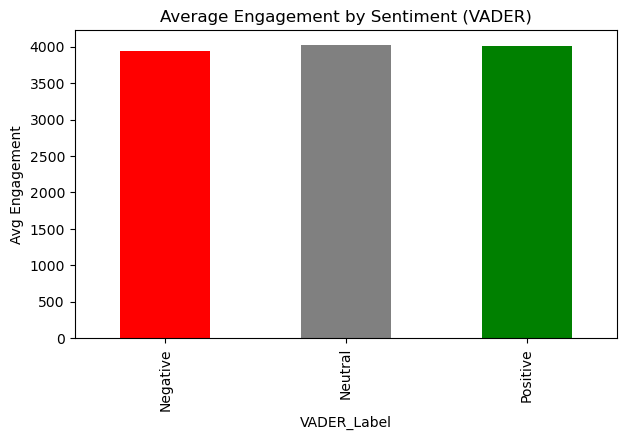

💾 Results saved to: D:\archive (3)\SocialMedia_Sentiment_Results.csv
Reached BERT step successfully.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import pipeline
import nltk
import re

nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))


# Load the Dataset

file_path = r"D:\archive (3)\Social Media Engagement Dataset.csv"
df = pd.read_csv(file_path, encoding='utf-8', on_bad_lines='skip')

print("✅ Loaded data with shape:", df.shape)
print("Columns:", df.columns.tolist())

# Try to detect likely text column (comment/caption)
text_column_candidates = [c for c in df.columns if 'comment' in c.lower() or 'caption' in c.lower() or 'text' in c.lower()]
if text_column_candidates:
    text_col = text_column_candidates[0]
else:
    text_col = df.columns[0]  # fallback
print(f"🗂 Using text column: {text_col}")


# Basic Text Cleaning

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)           # remove URLs
    text = re.sub(r'[@#]\w+', '', text)           # remove mentions/hashtags
    text = re.sub(r'[^a-z\s]', '', text)          # remove special chars
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

df['clean_text'] = df[text_col].astype(str).apply(clean_text)


# VADER Sentiment Analysis

vader = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    scores = vader.polarity_scores(str(text))
    return scores['compound']

df['VADER_Score'] = df['clean_text'].apply(get_vader_sentiment)

def classify_vader(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['VADER_Label'] = df['VADER_Score'].apply(classify_vader)

# -----------------------------
# 4️⃣ BERT Sentiment Analysis
# -----------------------------
print("⏳ Running BERT sentiment analysis (this may take a few minutes)...")

bert_pipeline = pipeline("sentiment-analysis")

# Apply BERT to a small sample if data is huge
sample_size = min(500, len(df))  # limit to 500 for speed
bert_results = bert_pipeline(df['clean_text'].iloc[:sample_size].tolist())

bert_df = pd.DataFrame(bert_results)
bert_df.columns = ['BERT_Label', 'BERT_Score']

df.loc[:sample_size-1, 'BERT_Label'] = bert_df['BERT_Label']
df.loc[:sample_size-1, 'BERT_Score'] = bert_df['BERT_Score']

print("✅ BERT analysis complete!")

# -----------------------------
# 5️⃣ Combine & Compare Sentiment Results
# -----------------------------
print("\nVADER Sentiment Distribution:")
print(df['VADER_Label'].value_counts())

if 'BERT_Label' in df.columns:
    print("\nBERT Sentiment Distribution (sampled):")
    print(df['BERT_Label'].value_counts())

# -----------------------------
# 6️⃣ Engagement Analysis (optional)
# -----------------------------
# Try to detect numeric engagement columns
engagement_cols = [c for c in df.columns if any(k in c.lower() for k in ['like','share','comment','view','engagement'])]

if engagement_cols:
    print("\n📊 Found engagement columns:", engagement_cols)
    df['Total_Engagement'] = df[engagement_cols].select_dtypes(include=np.number).sum(axis=1)
else:
    print("\n⚠️ No numeric engagement columns found. Skipping engagement analysis.")
    df['Total_Engagement'] = np.nan

# Group average engagement by sentiment
sentiment_engagement = df.groupby('VADER_Label')['Total_Engagement'].mean()

# -----------------------------
# 7️⃣ Visualization
# -----------------------------
plt.figure(figsize=(7,4))
sentiment_engagement.plot(kind='bar', color=['red','gray','green'])
plt.title('Average Engagement by Sentiment (VADER)')
plt.ylabel('Avg Engagement')
plt.show()

# -----------------------------
# 8️⃣ Save Results
# -----------------------------
output_path = r"D:\archive (3)\SocialMedia_Sentiment_Results.csv"
df.to_csv(output_path, index=False)
print(f"💾 Results saved to: {output_path}")
print("Reached BERT step successfully.")


# POST SENTIMENT ANALYSIS

In [4]:
try:
    import wordcloud  # noqa: F401
except Exception:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wordcloud", "--quiet"])

import os
import re
import string
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Configure matplotlib settings
plt.rcParams["figure.figsize"] = (8, 5)

LOAD DATASET

In [5]:
import pandas as pd
import os
import zipfile

DATA_PATHS = [
    r"D:\training.1600000.processed.noemoticon.csv (1).zip"
]

def load_sentiment140(paths):
    """Load Sentiment140 dataset from specified paths"""
    for p in paths:
        if os.path.exists(p):
            try:
                # --- Step 1: Extract CSV inside ZIP ---
                with zipfile.ZipFile(p, 'r') as zip_ref:
                    file_names = zip_ref.namelist()
                    print("📦 Files inside ZIP:", file_names)
                    # assume the first CSV inside is our dataset
                    csv_name = file_names[0]
                    with zip_ref.open(csv_name) as f:
                        df = pd.read_csv(f, encoding="latin-1", header=None)
                
                # --- Step 2: Ensure it has the right number of columns ---
                if df.shape[1] == 6:
                    df.columns = ["polarity", "id", "date", "query", "user", "text"]
                else:
                    print(f"⚠️ Unexpected column count: {df.shape[1]}")
                    print("Here are the first few rows to inspect:")
                    print(df.head())
                    raise ValueError("The dataset doesn't match expected Sentiment140 format.")
                
                return df

            except Exception as e:
                print(f"❌ Error reading {p}: {e}")

    print("⚠️ No valid dataset found at given paths.")
    return pd.DataFrame(columns=["polarity", "id", "date", "query", "user", "text"])

# --- Load dataset ---
df_raw = load_sentiment140(DATA_PATHS)

# --- Check ---
if df_raw.empty:
    raise ValueError("Dataset failed to load. Please check the file path or ZIP contents.")

# --- Normalize labels ---
label_map = {0: 0, 2: 1, 4: 2}
df_raw["label"] = df_raw["polarity"].map(label_map).astype(int)

# --- Keep only necessary columns ---
df = df_raw[["text", "label"]].copy()

print("✅ Loaded samples:", len(df))
print(df.head())

# --- Text cleaning function ---
def clean_text(s):
    s = s.lower()
    s = s.replace("@", "")
    s = s.replace("#", "")
    s = s.replace("http", "")
    return s

# --- Apply cleaning ---
df["clean_text"] = df["text"].astype(str).apply(clean_text)

print("\n✅ Cleaned text preview:")
print(df[["text", "clean_text"]].head(10))


📦 Files inside ZIP: ['training.1600000.processed.noemoticon.csv']
✅ Loaded samples: 1600000
                                                text  label
0  @switchfoot http://twitpic.com/2y1zl - Awww, t...      0
1  is upset that he can't update his Facebook by ...      0
2  @Kenichan I dived many times for the ball. Man...      0
3    my whole body feels itchy and like its on fire       0
4  @nationwideclass no, it's not behaving at all....      0

✅ Cleaned text preview:
                                                text  \
0  @switchfoot http://twitpic.com/2y1zl - Awww, t...   
1  is upset that he can't update his Facebook by ...   
2  @Kenichan I dived many times for the ball. Man...   
3    my whole body feels itchy and like its on fire    
4  @nationwideclass no, it's not behaving at all....   
5                      @Kwesidei not the whole crew    
6                                        Need a hug    
7  @LOLTrish hey  long time no see! Yes.. Rains a...   
8               @Ta

Exploratory Data Analysis

In [6]:
print(df.info())
print("\nLabel distribution (0=neg, 1=neutral, 2=pos):")
print(df["label"].value_counts(dropna=False).sort_index())

# Show a few samples
print("\nSample texts:")
RANDOM_SEED = len(df)
print(df.sample(min(5, len(df)), random_state=RANDOM_SEED))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 3 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   text        1600000 non-null  object
 1   label       1600000 non-null  int64 
 2   clean_text  1600000 non-null  object
dtypes: int64(1), object(2)
memory usage: 36.6+ MB
None

Label distribution (0=neg, 1=neutral, 2=pos):
label
0    800000
2    800000
Name: count, dtype: int64

Sample texts:
                                                      text  label  \
97739    Gagging for a jacket potato with Cheese and Be...      0   
1500721     God Bless and Goodnight, my fellow tweeters!!       2   
1422747  @brightflashburn No problem.  Have a nice sleep.       2   
1508006  @varshart158 hello  welcome to twitter...happy...      2   
512636    @mark_e_f Very jealous. 2 years since I've been       0   

                                                clean_text  
97739    gagging for a jacke

Text Preprocessing

In [7]:

import pandas as pd
import re
import os

# ✅ Path to your dataset
DATA_PATH = r"C:\Users\Ankit kumar\OneDrive\Documents\training.1600000.processed.noemoticon.csv"

# ✅ Load Sentiment140 dataset
def load_sentiment140(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Use correct encoding and handle commas properly
    df = pd.read_csv(path, encoding="latin-1", header=None)
    df.columns = ["polarity", "id", "date", "query", "user", "text"]
    return df

# ✅ Load data
df = load_sentiment140(DATA_PATH)

# ✅ Normalize labels (0 = negative, 2 = neutral, 4 = positive)
label_map = {0: 0, 2: 1, 4: 2}
df["label"] = df["polarity"].map(label_map)

# ✅ Define a text cleaning function
def clean_text(s):
    s = re.sub(r"http\S+|www\S+", "", s)     # remove URLs
    s = re.sub(r"@\w+", "", s)               # remove mentions
    s = re.sub(r"[^A-Za-z0-9\s]", "", s)     # remove special chars
    s = re.sub(r"\s+", " ", s).strip()       # remove extra spaces
    return s

# ✅ Apply cleaning
df["clean_text"] = df["text"].astype(str).apply(clean_text)

# ✅ Keep only relevant columns
df = df[["clean_text", "label"]]

# ✅ Show info
print("✅ Data loaded successfully!")
print("Total samples:", len(df))
print(df.head(5))


✅ Data loaded successfully!
Total samples: 1600000
                                          clean_text  label
0  A thats a bummer You shoulda got David Carr of...      0
1  is upset that he cant update his Facebook by t...      0
2  I dived many times for the ball Managed to sav...      0
3     my whole body feels itchy and like its on fire      0
4  no its not behaving at all im mad why am i her...      0


DATA VISULIZATION

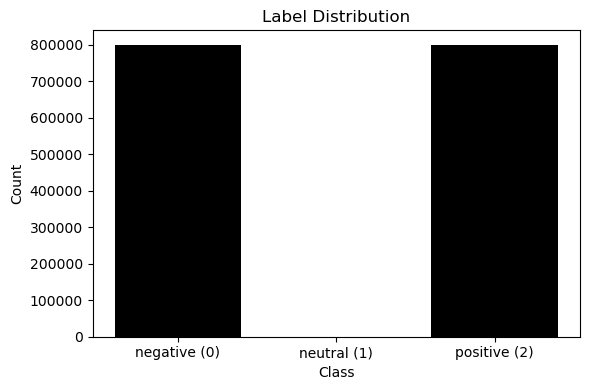

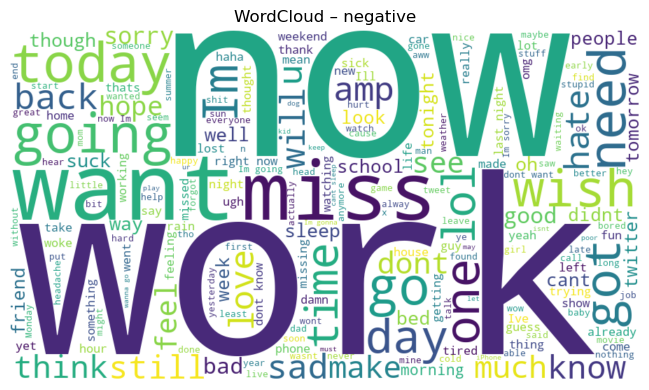

✅ Saved wordcloud to wordcloud_negative.png
[WARN] Not enough text for wordcloud: WordCloud – neutral


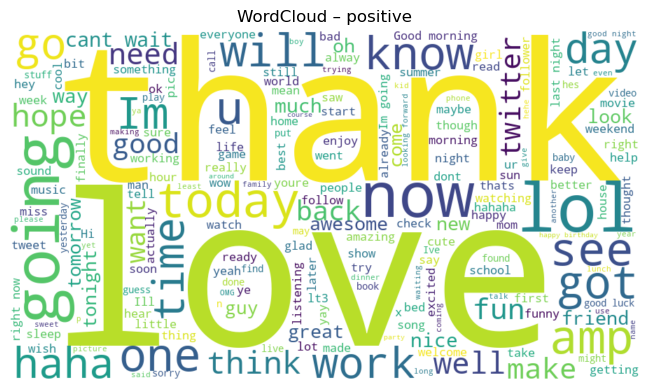

✅ Saved wordcloud to wordcloud_positive.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Assuming df is already loaded and has columns 'label' and 'clean_text'

# Count labels and plot distribution
counts = df["label"].value_counts().sort_index()
labels = ["negative (0)", "neutral (1)", "positive (2)"]
x = np.arange(len(labels))

plt.figure(figsize=(6,4))
plt.bar(x, [counts.get(i, 0) for i in range(3)], color=["black", "red", "black"])
plt.xticks(x, labels, rotation=0)
plt.title("Label Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# Function to plot and save wordcloud
def plot_wordcloud(text_series, title, filename):
    """Generate and save word cloud visualization"""
    text_blob = " ".join(text_series.dropna().astype(str).tolist())
    if len(text_blob) < 2:
        print(f"[WARN] Not enough text for wordcloud: {title}")
        return
    
    wc = WordCloud(width=900, height=500, background_color="white").generate(text_blob)
    
    plt.figure(figsize=(8,4))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    
    wc.to_file(filename)
    print(f"✅ Saved wordcloud to {filename}")


# Generate word clouds for each sentiment class
for lab, name in zip([0, 1, 2], ["negative", "neutral", "positive"]):
    subset = df.loc[df["label"] == lab, "clean_text"]
    plot_wordcloud(subset, f"WordCloud – {name}", f"wordcloud_{name}.png")


Train-Test Split

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Settings ---
RANDOM_SEED = 42         # define the random seed
MAX_SAMPLES = 120000

# assume `df` already exists and has columns "label" and "clean_text"
# Optionally reset index (not required, but often useful)
df = df.reset_index(drop=True)

# If dataset is large, create a balanced subsample (up to MAX_SAMPLES)
if len(df) > MAX_SAMPLES:
    df_list = []
    per_class = MAX_SAMPLES // 3
    for c in [0, 1, 2]:
        # number of available items for class c
        n_available = (df["label"] == c).sum()
        n_to_sample = min(per_class, n_available)
        if n_to_sample > 0:
            sub = df[df["label"] == c].sample(n=n_to_sample, random_state=RANDOM_SEED)
            df_list.append(sub)
        # if n_to_sample == 0 we skip (class absent)
    if len(df_list) == 0:
        # fallback: no class samples found — keep original df (or handle as you prefer)
        df_small = df.copy()
    else:
        df_small = pd.concat(df_list, axis=0).sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)
else:
    df_small = df.copy()

# features and labels
X = df_small["clean_text"].values
y = df_small["label"].values

# Perform stratified train-test split if there is more than one class
stratify_arg = y if len(np.unique(y)) > 1 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=stratify_arg
)

print("Train size:", len(X_train), "Test size:", len(X_test))


Train size: 64000 Test size: 16000


Feature Extraction

In [10]:
# imports
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# --- Ensure X_train / X_test exist and are text --- 
# Convert to plain Python strings to avoid issues with mixed types/NaNs
X_train_text = np.asarray(X_train).astype(str)
X_test_text  = np.asarray(X_test).astype(str)

# TF-IDF
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=50000)
Xtr_tfidf = tfidf.fit_transform(X_train_text)
Xte_tfidf = tfidf.transform(X_test_text)
print("TF-IDF shapes:", Xtr_tfidf.shape, Xte_tfidf.shape)

# Count Vectorizer
count_vec = CountVectorizer(stop_words="english", ngram_range=(1, 2), max_features=50000)
Xtr_count = count_vec.fit_transform(X_train_text)
Xte_count = count_vec.transform(X_test_text)
print("Count shapes:", Xtr_count.shape, Xte_count.shape)


TF-IDF shapes: (64000, 50000) (16000, 50000)
Count shapes: (64000, 50000) (16000, 50000)


Model Training and Evaluation


=== LogisticRegression with TF-IDF ===
Accuracy: 0.7607
              precision    recall  f1-score   support

           0     0.7721    0.7398    0.7556      8000
           2     0.7502    0.7816    0.7656      8000

    accuracy                         0.7607     16000
   macro avg     0.7611    0.7607    0.7606     16000
weighted avg     0.7611    0.7607    0.7606     16000



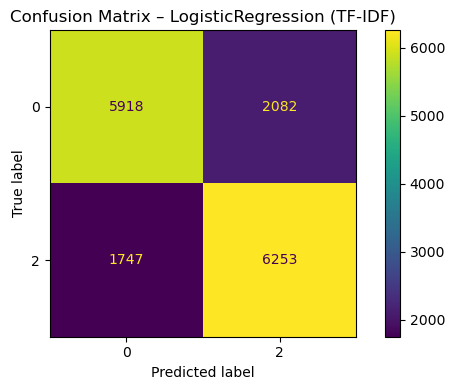


=== MultinomialNB with TF-IDF ===
Accuracy: 0.7472
              precision    recall  f1-score   support

           0     0.7396    0.7631    0.7512      8000
           2     0.7553    0.7312    0.7431      8000

    accuracy                         0.7472     16000
   macro avg     0.7474    0.7472    0.7471     16000
weighted avg     0.7474    0.7472    0.7471     16000



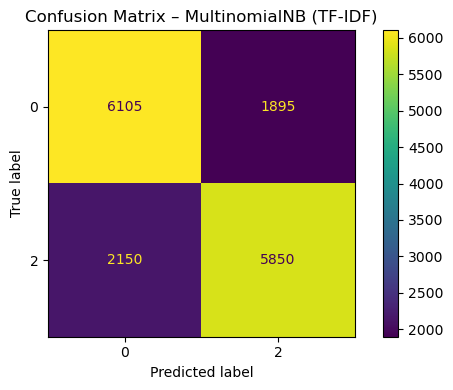


=== LinearSVC with TF-IDF ===
Accuracy: 0.7424
              precision    recall  f1-score   support

           0     0.7480    0.7310    0.7394      8000
           2     0.7370    0.7538    0.7453      8000

    accuracy                         0.7424     16000
   macro avg     0.7425    0.7424    0.7423     16000
weighted avg     0.7425    0.7424    0.7423     16000



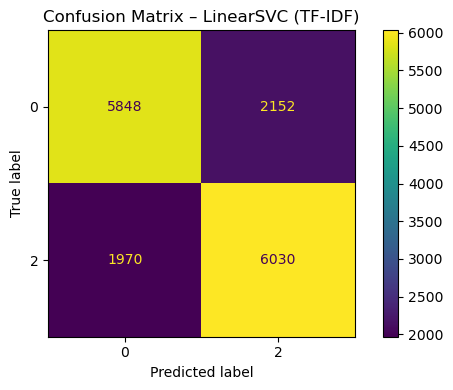

MemoryError: Unable to allocate 11.9 GiB for an array with shape (64000, 50000) and data type float32

In [11]:
# --- Robust evaluation cell: paste & run ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Make sure RANDOM_SEED exists
try:
    RANDOM_SEED
except NameError:
    RANDOM_SEED = 42

def _to_dense_if_needed(X):
    """Return dense array if model can't handle sparse input (RandomForest)."""
    try:
        from scipy import sparse
        if sparse.issparse(X):
            return X.toarray()
    except Exception:
        pass
    return X

def eval_and_report(model, Xtr, ytr, Xte, yte, model_name, feature_name):
    """Train model and generate evaluation report (handles dense conversion where needed)."""
    Xtr_fit = Xtr
    Xte_pred = Xte
    needs_dense = isinstance(model, RandomForestClassifier)
    if needs_dense:
        Xtr_fit = _to_dense_if_needed(Xtr)
        Xte_pred = _to_dense_if_needed(Xte)

    model.fit(Xtr_fit, ytr)
    preds = model.predict(Xte_pred)

    acc = accuracy_score(yte, preds)
    print(f"\n=== {model_name} with {feature_name} ===")
    print("Accuracy:", round(acc, 4))
    print(classification_report(yte, preds, digits=4))

    labels = sorted(np.unique(np.concatenate([ytr, yte])))
    cm = confusion_matrix(yte, preds, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    plt.figure(figsize=(6, 4))
    disp.plot(values_format="d", ax=plt.gca())
    plt.title(f"Confusion Matrix – {model_name} ({feature_name})")
    plt.tight_layout()
    plt.show()

    return acc

# Check that all variables exist
required_vars = ["Xtr_tfidf", "Xte_tfidf", "Xtr_count", "Xte_count", "y_train", "y_test"]
for v in required_vars:
    if v not in globals():
        raise NameError(f"Required variable '{v}' not found. Run TF-IDF/CountVectorizer cells first.")

results = []

# Initialize models
models = [
    ("LogisticRegression", LogisticRegression(max_iter=200, random_state=RANDOM_SEED)),
    ("MultinomialNB", MultinomialNB()),
    ("LinearSVC", LinearSVC(random_state=RANDOM_SEED)),
    ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)),
]

# Features
feature_sets = {
    "TF-IDF": (Xtr_tfidf, Xte_tfidf),
    "Count": (Xtr_count, Xte_count)
}

# Evaluate
for feat_name, (Xtr, Xte) in feature_sets.items():
    for model_name, model in models:
        acc = eval_and_report(model, Xtr, y_train, Xte, y_test, model_name, feat_name)
        results.append({"model": model_name, "features": feat_name, "accuracy": acc})

# Summary
res_df = pd.DataFrame(results).sort_values(["accuracy"], ascending=False).reset_index(drop=True)
print("\n=== Summary Leaderboard (by Accuracy) ===")
print(res_df)


Feature Interpretability

In [12]:
from collections import Counter

def top_ngrams_per_class(X_texts, y_labels, vectorizer, top_k=15):
    """Extract top n-grams for each class"""
    X_all = vectorizer.fit_transform(X_texts)
    vocab = np.array(vectorizer.get_feature_names_out())
    tops = {}
    for c in sorted(set(y_labels)):
        idx = np.where(y_labels == c)[0]
        if len(idx) == 0:
            tops[c] = []
            continue
        Xc = X_all[idx]
        freqs = np.asarray(Xc.sum(axis=0)).ravel()
        top_idx = np.argsort(freqs)[::-1][:top_k]
        tops[c] = list(zip(vocab[top_idx], freqs[top_idx].tolist()))
    return tops

# Extract top tokens for each class
vec_small = CountVectorizer(stop_words="english", ngram_range=(1,2), max_features=20000)
tops = top_ngrams_per_class(np.array(X), np.array(y), vec_small, top_k=15)

for c in [0,1,2]:
    print(f"\nTop tokens for class {c} (0=negative, 1=neutral, 2=positive):")
    for tok, freq in tops.get(c, []):
        print(f"{tok:25s} {int(freq)}")


Top tokens for class 0 (0=negative, 1=neutral, 2=positive):
im                        5031
just                      3180
dont                      2333
work                      2296
like                      2045
day                       1889
today                     1784
got                       1665
really                    1613
going                     1586
good                      1541
miss                      1535
want                      1527
know                      1335
time                      1335

Top tokens for class 1 (0=negative, 1=neutral, 2=positive):

Top tokens for class 2 (0=negative, 1=neutral, 2=positive):
im                        3836
just                      3077
good                      2988
love                      2232
day                       2177
like                      1894
lol                       1741
thanks                    1690
got                       1478
time                      1465
going                     1451
today      

Prediction Examples

In [15]:


# --------------------------
# SAFETY CHECK: res_df must exist
# --------------------------
try:
    best_row = res_df.iloc[0]
except NameError:
    raise NameError("❌ ERROR: 'res_df' is not defined. You must run the model comparison code first.")

# Extract best feature & model
best_feat = best_row["features"]
best_model_name = best_row["model"]

print("\nBest combination:", best_model_name, "with", best_feat)


# --------------------------
# Step 2: Select Best Features
# --------------------------
if best_feat == "TF-IDF":
    Xtr_best, Xte_best = Xtr_tfidf, Xte_tfidf
    vec_used = tfidf

elif best_feat == "Count":
    Xtr_best, Xte_best = Xtr_count, Xte_count
    vec_used = count_vec

else:
    raise NameError(f"❌ Feature matrices for '{best_feat}' not found.")


# --------------------------
# STEP 2.5: Create Model Factory
# --------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

def make_model(name):
    """Return model instance by name."""
    if name == "LogisticRegression":
        return LogisticRegression(max_iter=200)

    elif name == "MultinomialNB":
        return MultinomialNB()

    elif name == "LinearSVC":
        return LinearSVC()

    elif name == "RandomForest":
        return RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_SEED,
            n_jobs=-1
        )

    else:
        raise ValueError(f"❌ Unknown model name: {name}")


# --------------------------
# Train Best Model
# --------------------------
best_model = make_model(best_model_name)
best_model.fit(Xtr_best, y_train)

print("\n✅ Best model trained successfully!")


# --------------------------
# Step 3: Show Few Predictions
# --------------------------
n_show = min(10, len(X_test))

print("\n🔍 Showing predictions on sample test data:")

for i in range(n_show):
    text = X_test[i]
    true_lab = y_test[i]
    
    # FIXED: Reshape Xte_best[i] to 2D
    pred_lab = best_model.predict(Xte_best[i].reshape(1, -1))[0]

    print(f"\nText: {text}\nTrue: {true_lab}   Pred: {pred_lab}")


NameError: ❌ ERROR: 'res_df' is not defined. You must run the model comparison code first.

In [ ]:

# # --------------------------
# # Step 2: Select Best Model
# # --------------------------
# best_row = res_df.iloc[0]
# best_feat = best_row["features"]
# best_model_name = best_row["model"]
# print("\nBest combination:", best_model_name, "with", best_feat)


# # Select best feature vectors
# if best_feat == "TF-IDF":
#     Xtr_best, Xte_best = Xtr_tfidf, Xte_tfidf
#     vec_used = tfidf
# elif best_feat == "Count":
#     Xtr_best, Xte_best = Xtr_count, Xte_count
#     vec_used = count_vec
# else:
#     raise NameError(f"Feature matrices for '{best_feat}' not found.")


# # Create model instance dynamically
# def make_model(name):
#     """Return model instance by name"""
#     if name == "LogisticRegression":
#         return LogisticRegression(max_iter=200)
#     elif name == "MultinomialNB":
#         return MultinomialNB()
#     elif name == "LinearSVC":
#         return LinearSVC()
#     elif name == "RandomForest":
#         return RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)
#     else:
#         raise ValueError(f"Unknown model name: {name}")


# # Train best model
# best_model = make_model(best_model_name)
# best_model.fit(Xtr_best, y_train)


# # --------------------------
# # Step 3: Predict Sentiment for New Comment
# # --------------------------
# user_comment = input("\n💬 Enter a comment to analyze its sentiment: ")

# # Convert to vector form
# comment_vector = vec_used.transform([user_comment])

# # Predict sentiment
# pred_label = best_model.predict(comment_vector)[0]

# # Optional: define label meanings if 0=Negative, 1=Neutral, 2=Positive
# sentiment_map = {0: "Negative 😞", 1: "Neutral 😐", 2: "Positive 😊"}
# sentiment_text = sentiment_map.get(pred_label, str(pred_label))

# print(f"\nPredicted Sentiment: {sentiment_text}")
